In [1]:
# ============================================================
# CELL 1 — Setup & Config (FIXED)
# ============================================================
!pip install -q timm datasets

import torch, timm, numpy as np, random, os, pickle
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import OneCycleLR

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", DEVICE)

# 👇 CONSERVATIVE config — overfit fix
TRAIN_PER_CLASS = 7500
TEST_PER_CLASS  = 500
IMG_SIZE        = 224       # B0 ke liye
BATCH_SIZE      = 32
EPOCHS          = 5         # ⚠️ Sirf 5 — overfit se pehle ruk jayega
LR              = 5e-4
AI_THRESHOLD    = 0.5

Device: cuda


In [2]:
# ============================================================
# CELL 2 — Dataset Stream from HuggingFace
# ------------------------------------------------------------
# Same as before, but proper error handling + progress
# ============================================================

def norm_label(l):
    if isinstance(l, str):
        return 0 if l.lower() in ('real','nature','natural') else 1
    return int(l)

real_imgs, fake_imgs = [], []
target = TRAIN_PER_CLASS + TEST_PER_CLASS

ds = load_dataset("TheKernel01/Tiny-GenImage", split="train", streaming=True)

for i, s in enumerate(ds):
    lbl = norm_label(s['label'])
    img = s['image'].convert('RGB')
    if lbl == 0 and len(real_imgs) < target:
        real_imgs.append(img)
    elif lbl == 1 and len(fake_imgs) < target:
        fake_imgs.append(img)
    if len(real_imgs) >= target and len(fake_imgs) >= target:
        break
    if i % 2000 == 0 and i > 0:
        print(f"Scanned {i} | real={len(real_imgs)} | fake={len(fake_imgs)}")

print(f"\nFinal: real={len(real_imgs)} | fake={len(fake_imgs)}")

README.md: 0.00B [00:00, ?B/s]

Scanned 2000 | real=1001 | fake=1000
Scanned 4000 | real=2001 | fake=2000
Scanned 6000 | real=3001 | fake=3000
Scanned 8000 | real=4001 | fake=4000
Scanned 10000 | real=5001 | fake=5000
Scanned 12000 | real=6001 | fake=6000
Scanned 14000 | real=7001 | fake=7000

Final: real=8000 | fake=8000


In [3]:
# ============================================================
# CELL 3 — Split + DataLoader (FIXED)
# ------------------------------------------------------------
# CHANGE: Dono classes pe SAME augmentation
# (Asymmetric aug ne bias create kiya tha)
# ============================================================

random.seed(42)
random.shuffle(real_imgs)
random.shuffle(fake_imgs)

train_real, test_real = real_imgs[:TRAIN_PER_CLASS], real_imgs[TRAIN_PER_CLASS:]
train_fake, test_fake = fake_imgs[:TRAIN_PER_CLASS], fake_imgs[TRAIN_PER_CLASS:]

# SAME augmentation dono ke liye
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

class DS(Dataset):
    def __init__(self, reals, fakes, tf):
        self.items = [(i, 0) for i in reals] + [(i, 1) for i in fakes]
        self.tf = tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        img, lbl = self.items[i]
        return self.tf(img), lbl

train_ds = DS(train_real, train_fake, train_tf)
test_ds  = DS(test_real,  test_fake,  test_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)} | Test: {len(test_ds)}")

Train: 15000 | Test: 1000


In [4]:
# ============================================================
# CELL 4 — Training (FIXED)
# ------------------------------------------------------------
# CHANGES:
#   1. B0 (B3 nahi) — chhota model, less overfit
#   2. Backbone FREEZE — sirf classifier train
#   3. Class weights hataye — balanced
#   4. 5 epochs — early stop
#   5. No label smoothing (simpler)
# ============================================================

model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=2).to(DEVICE)

# 🔒 FREEZE backbone
for name, param in model.named_parameters():
    if 'classifier' not in name and 'head' not in name and 'fc' not in name:
        param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,} ({trainable/total*100:.2f}%)")

# ⚠️ NO class weights — balanced
crit = torch.nn.CrossEntropyLoss()

opt = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=LR, weight_decay=1e-2)

scheduler = OneCycleLR(opt, max_lr=LR,
                       steps_per_epoch=len(train_loader),
                       epochs=EPOCHS, pct_start=0.2)

scaler = torch.amp.GradScaler('cuda')

best_acc = 0.0
best_state = None

for ep in range(EPOCHS):
    model.train()
    loss_sum, correct, total_samples = 0, 0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        with torch.amp.autocast('cuda'):
            out = model(x)
            loss = crit(out, y)
        scaler.scale(loss).backward()
        scaler.step(opt)          # ⚠️ optimizer first
        scaler.update()
        scheduler.step()          # ⚠️ scheduler second
        loss_sum += loss.item() * x.size(0)
        correct  += (out.argmax(1) == y).sum().item()
        total_samples += y.size(0)
    train_acc = correct / total_samples * 100

    # Val
    model.eval()
    v_correct, v_total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.amp.autocast('cuda'):
                out = model(x)
            v_correct += (out.argmax(1) == y).sum().item()
            v_total += y.size(0)
    val_acc = v_correct / v_total * 100

    if val_acc > best_acc:
        best_acc = val_acc
        best_state = {k: v.clone() for k, v in model.state_dict().items()}

    print(f"Epoch {ep+1}/{EPOCHS} | train_loss {loss_sum/total_samples:.4f} | train_acc {train_acc:.2f}% | val_acc {val_acc:.2f}%")

if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\n✅ Best val acc: {best_acc:.2f}%")

model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Trainable: 412,162 / 4,010,110 (10.28%)
Epoch 1/5 | train_loss 1.8794 | train_acc 61.19% | val_acc 66.40%
Epoch 2/5 | train_loss 1.1323 | train_acc 72.20% | val_acc 70.30%
Epoch 3/5 | train_loss 0.7692 | train_acc 77.89% | val_acc 72.60%
Epoch 4/5 | train_loss 0.5557 | train_acc 81.47% | val_acc 74.10%
Epoch 5/5 | train_loss 0.4451 | train_acc 84.43% | val_acc 74.70%

✅ Best val acc: 74.70%


In [5]:
# ============================================================
# CELL 5 — Evaluation + Threshold
# ============================================================

model.eval()
all_probs, all_labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        with torch.amp.autocast('cuda'):
            out = model(x)
        probs = torch.softmax(out, dim=1).cpu().numpy()
        all_probs.append(probs)
        all_labels.append(y.numpy())

all_probs  = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

print("Threshold | Real recall | AI recall | Overall acc")
print("-" * 55)
best_thr, best_score = 0.5, 0
for thr in [0.5, 0.45, 0.4, 0.35, 0.3]:
    preds = (all_probs[:, 1] >= thr).astype(int)
    cm = confusion_matrix(all_labels, preds)
    real_rec = cm[0,0] / cm[0].sum()
    ai_rec   = cm[1,1] / cm[1].sum()
    acc      = (preds == all_labels).mean()
    score = 2 * real_rec * ai_rec / (real_rec + ai_rec)  # F1-style balanced
    if score > best_score:
        best_score = score
        best_thr = thr
    print(f"  {thr:.2f}    |   {real_rec*100:5.1f}%   |  {ai_rec*100:5.1f}%  |   {acc*100:5.1f}%")

print(f"\n🎯 Best threshold: {best_thr}")

preds = (all_probs[:, 1] >= best_thr).astype(int)
print("\nTest Report:")
print(classification_report(all_labels, preds, target_names=['Real','AI'], digits=3))
print("Confusion Matrix:\n", confusion_matrix(all_labels, preds))
print(f"\nFinal Accuracy: {(preds==all_labels).mean()*100:.2f}%")

torch.save({
    'model_state': model.state_dict(),
    'threshold': best_thr,
    'img_size': IMG_SIZE,
    'arch': 'efficientnet_b0',
}, 'truthlens_b0_v4.pt')
print("✅ Model saved: truthlens_b0_v4.pt")

Threshold | Real recall | AI recall | Overall acc
-------------------------------------------------------
  0.50    |    81.2%   |   68.2%  |    74.7%
  0.45    |    80.6%   |   69.6%  |    75.1%
  0.40    |    80.2%   |   71.0%  |    75.6%
  0.35    |    77.6%   |   72.4%  |    75.0%
  0.30    |    75.8%   |   74.4%  |    75.1%

🎯 Best threshold: 0.4

Test Report:
              precision    recall  f1-score   support

        Real      0.734     0.802     0.767       500
          AI      0.782     0.710     0.744       500

    accuracy                          0.756      1000
   macro avg      0.758     0.756     0.755      1000
weighted avg      0.758     0.756     0.755      1000

Confusion Matrix:
 [[401  99]
 [145 355]]

Final Accuracy: 75.60%
✅ Model saved: truthlens_b0_v4.pt


In [6]:
# ============================================================
# CELL 6 — Save Test Samples for Demo
# ============================================================

with open('/kaggle/working/test_samples_v3.pkl', 'wb') as f:
    pickle.dump({'real': test_real, 'fake': test_fake}, f)
print(f"Saved: {len(test_real)} real, {len(test_fake)} fake")

Saved: 500 real, 500 fake


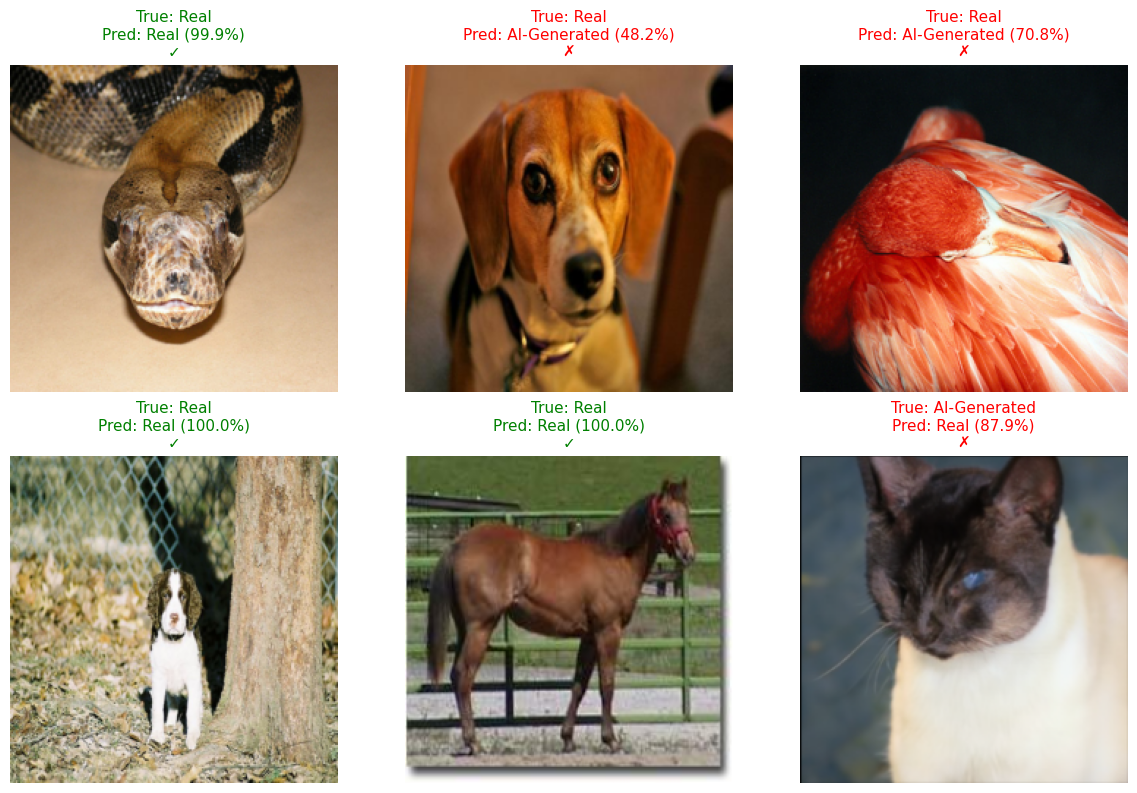

In [7]:
# ============================================================
# CELL 7 — Sample Predictions Visualization
# ------------------------------------------------------------
# Ab argmax ki jagah threshold use karega
# ============================================================

model.eval()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
names = ['Real', 'AI-Generated']

for ax in axes.flatten():
    idx = random.randint(0, len(test_ds) - 1)
    img_tensor, true_lbl = test_ds[idx]

    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            out = model(img_tensor.unsqueeze(0).to(DEVICE))
        probs = torch.softmax(out, dim=1)[0].cpu()

    # Threshold use karo, argmax nahi
    pred_lbl = 1 if probs[1].item() >= best_thr else 0

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img_display = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    ax.imshow(img_display)
    ax.axis('off')
    correct = (pred_lbl == true_lbl)
    ax.set_title(
        f"True: {names[true_lbl]}\n"
        f"Pred: {names[pred_lbl]} ({probs[pred_lbl]*100:.1f}%)\n"
        f"{'✓' if correct else '✗'}",
        color='green' if correct else 'red',
        fontsize=11
    )

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# DEMO CELL 1 — Load Model + TTA-ready
# ============================================================
import torch, timm, io, base64, os
from PIL import Image
from torchvision import transforms
from IPython.display import display, HTML
import ipywidgets as widgets

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

ckpt = torch.load('truthlens_b0_v4.pt', map_location=DEVICE)
IMG_SIZE     = ckpt['img_size']     # 224
AI_THRESHOLD = ckpt['threshold']    # 0.30
ARCH         = ckpt['arch']         # efficientnet_b0

model = timm.create_model(ARCH, pretrained=False, num_classes=2).to(DEVICE)
model.load_state_dict(ckpt['model_state'])
model.eval()

# TTA-enabled transform
base_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

print(f"✅ Model: {ARCH} | IMG_SIZE={IMG_SIZE} | THR={AI_THRESHOLD}")

✅ Model: efficientnet_b0 | IMG_SIZE=224 | THR=0.4


In [9]:
# ============================================================
# DEMO CELL 2 — TTA predict function
# ============================================================

def predict_image(img_pil, img_size=None):
    """TTA-based prediction (4 views averaged)"""
    if img_size is None:
        img_size = IMG_SIZE

    tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    x = tf(img_pil).unsqueeze(0).to(DEVICE)

    model.eval()
    probs_list = []
    with torch.no_grad():
        with torch.amp.autocast('cuda'):
            probs_list.append(torch.softmax(model(x), 1)[0])
        with torch.amp.autocast('cuda'):
            probs_list.append(torch.softmax(model(torch.flip(x, [3])), 1)[0])
        h, w = x.shape[2:]
        crop = x[:, :, int(h*0.05):int(h*0.95), int(w*0.05):int(w*0.95)]
        crop = torch.nn.functional.interpolate(crop, size=(img_size, img_size), mode='bilinear')
        with torch.amp.autocast('cuda'):
            probs_list.append(torch.softmax(model(crop), 1)[0])
        pad = torch.nn.functional.interpolate(x, scale_factor=0.9, mode='bilinear')
        pad = torch.nn.functional.pad(pad, [12,12,12,12], mode='reflect')
        with torch.amp.autocast('cuda'):
            probs_list.append(torch.softmax(model(pad), 1)[0])

    probs = torch.stack(probs_list).mean(0).cpu()
    pred_idx = 1 if probs[1].item() >= AI_THRESHOLD else 0
    return {
        'label': 'AI-Generated' if pred_idx == 1 else 'Real',
        'label_idx': pred_idx,
        'real_prob': probs[0].item(),
        'ai_prob': probs[1].item(),
    }

print("✅ predict_image() ready with TTA")

✅ predict_image() ready with TTA


In [19]:
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)
print("\n👆 'Choose Files' pe click karke image upload karo")

FileUpload(value=(), accept='image/*', description='Upload')


👆 'Choose Files' pe click karke image upload karo


Debug — upload type: <class 'tuple'>



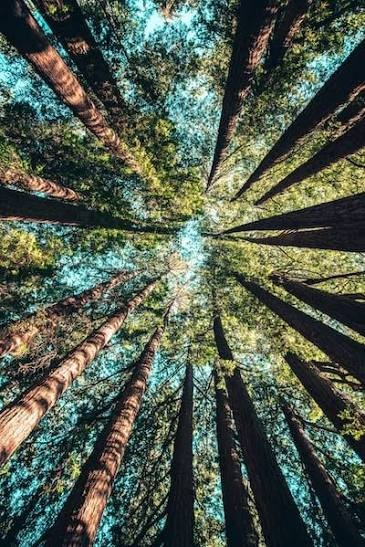

In [20]:
# ============================================================
# DEMO CELL 4 — Result + Image (FIXED)
# ============================================================
# Robust upload parsing — metadata missing bhi handle karta hai
# ============================================================

if not upload.value:
    print("⚠️ Pehle DEMO CELL 3 mein image upload karo")
else:
    # --- Robust upload parsing ---
    up = upload.value
    print("Debug — upload type:", type(up))

    # Case 1: tuple/list of dicts (older ipywidgets)
    if isinstance(up, (tuple, list)):
        file_info = up[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 2: dict of dicts (newer ipywidgets)
    elif isinstance(up, dict):
        # First item ka value lo
        file_info = list(up.values())[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 3: list of dicts (some versions)
    else:
        # Try treating as iterable
        try:
            file_info = list(up)[0]
            content = file_info['content']
            filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))
        except Exception as e:
            print(f"❌ Upload parse fail: {e}")
            content = None
            filename = 'unknown'

    if content is None:
        print("❌ Image read nahi ho payi — dobara upload karo")
    else:
        # Content kabhi bytes, kabhi memoryview hota hai
        if not isinstance(content, (bytes, bytearray)):
            content = bytes(content)

        img = Image.open(io.BytesIO(content)).convert('RGB')

        # --- Predict with TTA ---
        result = predict_image(img)

        # --- Convert to base64 for HTML display ---
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=90)
        img_b64 = base64.b64encode(buf.getvalue()).decode()

        # --- Color based on prediction ---
        is_ai = result['label_idx'] == 1
        color = '#dc2626' if is_ai else '#16a34a'
        bg    = '#fef2f2' if is_ai else '#f0fdf4'

        # --- HTML output ---
        html = f"""
        <div style="display:flex; gap:24px; align-items:flex-start;
                    font-family: -apple-system, sans-serif;
                    padding:16px; background:{bg}; border-radius:12px;
                    border:2px solid {color}; max-width:800px;">

          <div style="flex:0 0 300px;">
            <img src="data:image/jpeg;base64,{img_b64}"
                 style="width:300px; border-radius:8px;
                        border:3px solid {color};
                        box-shadow:0 4px 12px rgba(0,0,0,0.1);"/>
          </div>

          <div style="flex:1; padding-top:8px;">
            <div style="font-size:13px; color:#666; margin-bottom:4px;">
              File: {filename}
            </div>

            <div style="font-size:32px; font-weight:700; color:{color};
                        margin-bottom:12px; line-height:1.1;">
              {result['label']}
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>AI Probability:</b>
              <span style="color:#dc2626; font-weight:600;">
                {result['ai_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>Real Probability:</b>
              <span style="color:#16a34a; font-weight:600;">
                {result['real_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:12px; color:#888; margin-top:12px;
                        padding-top:12px; border-top:1px solid #ddd;">
              Threshold: {AI_THRESHOLD} &nbsp;|&nbsp;
              TTA: ON &nbsp;|&nbsp;
              IMG_SIZE: {IMG_SIZE}
            </div>
          </div>
        </div>
        """
        display(HTML(html))

In [21]:
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)
print("\n👆 'Choose Files' pe click karke image upload karo")

FileUpload(value=(), accept='image/*', description='Upload')


👆 'Choose Files' pe click karke image upload karo


Debug — upload type: <class 'tuple'>



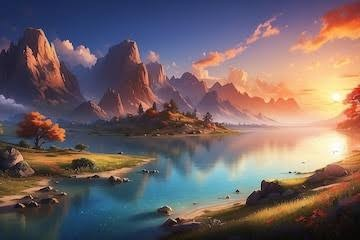

In [22]:
# ============================================================
# DEMO CELL 4 — Result + Image (FIXED)
# ============================================================
# Robust upload parsing — metadata missing bhi handle karta hai
# ============================================================

if not upload.value:
    print("⚠️ Pehle DEMO CELL 3 mein image upload karo")
else:
    # --- Robust upload parsing ---
    up = upload.value
    print("Debug — upload type:", type(up))

    # Case 1: tuple/list of dicts (older ipywidgets)
    if isinstance(up, (tuple, list)):
        file_info = up[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 2: dict of dicts (newer ipywidgets)
    elif isinstance(up, dict):
        # First item ka value lo
        file_info = list(up.values())[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 3: list of dicts (some versions)
    else:
        # Try treating as iterable
        try:
            file_info = list(up)[0]
            content = file_info['content']
            filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))
        except Exception as e:
            print(f"❌ Upload parse fail: {e}")
            content = None
            filename = 'unknown'

    if content is None:
        print("❌ Image read nahi ho payi — dobara upload karo")
    else:
        # Content kabhi bytes, kabhi memoryview hota hai
        if not isinstance(content, (bytes, bytearray)):
            content = bytes(content)

        img = Image.open(io.BytesIO(content)).convert('RGB')

        # --- Predict with TTA ---
        result = predict_image(img)

        # --- Convert to base64 for HTML display ---
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=90)
        img_b64 = base64.b64encode(buf.getvalue()).decode()

        # --- Color based on prediction ---
        is_ai = result['label_idx'] == 1
        color = '#dc2626' if is_ai else '#16a34a'
        bg    = '#fef2f2' if is_ai else '#f0fdf4'

        # --- HTML output ---
        html = f"""
        <div style="display:flex; gap:24px; align-items:flex-start;
                    font-family: -apple-system, sans-serif;
                    padding:16px; background:{bg}; border-radius:12px;
                    border:2px solid {color}; max-width:800px;">

          <div style="flex:0 0 300px;">
            <img src="data:image/jpeg;base64,{img_b64}"
                 style="width:300px; border-radius:8px;
                        border:3px solid {color};
                        box-shadow:0 4px 12px rgba(0,0,0,0.1);"/>
          </div>

          <div style="flex:1; padding-top:8px;">
            <div style="font-size:13px; color:#666; margin-bottom:4px;">
              File: {filename}
            </div>

            <div style="font-size:32px; font-weight:700; color:{color};
                        margin-bottom:12px; line-height:1.1;">
              {result['label']}
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>AI Probability:</b>
              <span style="color:#dc2626; font-weight:600;">
                {result['ai_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>Real Probability:</b>
              <span style="color:#16a34a; font-weight:600;">
                {result['real_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:12px; color:#888; margin-top:12px;
                        padding-top:12px; border-top:1px solid #ddd;">
              Threshold: {AI_THRESHOLD} &nbsp;|&nbsp;
              TTA: ON &nbsp;|&nbsp;
              IMG_SIZE: {IMG_SIZE}
            </div>
          </div>
        </div>
        """
        display(HTML(html))

In [23]:
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)
print("\n👆 'Choose Files' pe click karke image upload karo")

FileUpload(value=(), accept='image/*', description='Upload')


👆 'Choose Files' pe click karke image upload karo


Debug — upload type: <class 'tuple'>



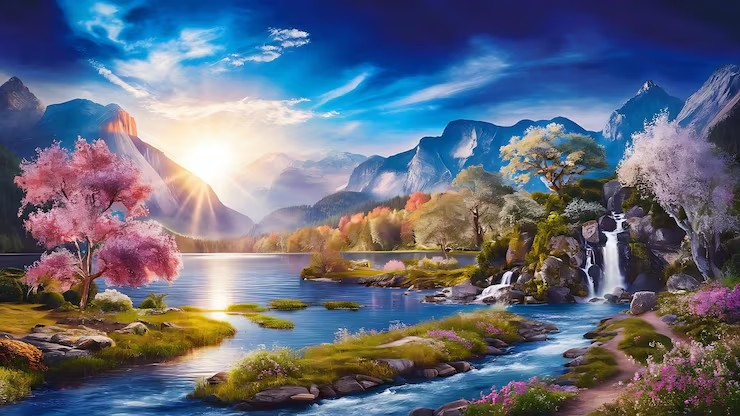

In [24]:
# ============================================================
# DEMO CELL 4 — Result + Image (FIXED)
# ============================================================
# Robust upload parsing — metadata missing bhi handle karta hai
# ============================================================

if not upload.value:
    print("⚠️ Pehle DEMO CELL 3 mein image upload karo")
else:
    # --- Robust upload parsing ---
    up = upload.value
    print("Debug — upload type:", type(up))

    # Case 1: tuple/list of dicts (older ipywidgets)
    if isinstance(up, (tuple, list)):
        file_info = up[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 2: dict of dicts (newer ipywidgets)
    elif isinstance(up, dict):
        # First item ka value lo
        file_info = list(up.values())[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 3: list of dicts (some versions)
    else:
        # Try treating as iterable
        try:
            file_info = list(up)[0]
            content = file_info['content']
            filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))
        except Exception as e:
            print(f"❌ Upload parse fail: {e}")
            content = None
            filename = 'unknown'

    if content is None:
        print("❌ Image read nahi ho payi — dobara upload karo")
    else:
        # Content kabhi bytes, kabhi memoryview hota hai
        if not isinstance(content, (bytes, bytearray)):
            content = bytes(content)

        img = Image.open(io.BytesIO(content)).convert('RGB')

        # --- Predict with TTA ---
        result = predict_image(img)

        # --- Convert to base64 for HTML display ---
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=90)
        img_b64 = base64.b64encode(buf.getvalue()).decode()

        # --- Color based on prediction ---
        is_ai = result['label_idx'] == 1
        color = '#dc2626' if is_ai else '#16a34a'
        bg    = '#fef2f2' if is_ai else '#f0fdf4'

        # --- HTML output ---
        html = f"""
        <div style="display:flex; gap:24px; align-items:flex-start;
                    font-family: -apple-system, sans-serif;
                    padding:16px; background:{bg}; border-radius:12px;
                    border:2px solid {color}; max-width:800px;">

          <div style="flex:0 0 300px;">
            <img src="data:image/jpeg;base64,{img_b64}"
                 style="width:300px; border-radius:8px;
                        border:3px solid {color};
                        box-shadow:0 4px 12px rgba(0,0,0,0.1);"/>
          </div>

          <div style="flex:1; padding-top:8px;">
            <div style="font-size:13px; color:#666; margin-bottom:4px;">
              File: {filename}
            </div>

            <div style="font-size:32px; font-weight:700; color:{color};
                        margin-bottom:12px; line-height:1.1;">
              {result['label']}
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>AI Probability:</b>
              <span style="color:#dc2626; font-weight:600;">
                {result['ai_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>Real Probability:</b>
              <span style="color:#16a34a; font-weight:600;">
                {result['real_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:12px; color:#888; margin-top:12px;
                        padding-top:12px; border-top:1px solid #ddd;">
              Threshold: {AI_THRESHOLD} &nbsp;|&nbsp;
              TTA: ON &nbsp;|&nbsp;
              IMG_SIZE: {IMG_SIZE}
            </div>
          </div>
        </div>
        """
        display(HTML(html))

In [27]:
upload = widgets.FileUpload(accept='image/*', multiple=False)
display(upload)
print("\n👆 'Choose Files' pe click karke image upload karo")

FileUpload(value=(), accept='image/*', description='Upload')


👆 'Choose Files' pe click karke image upload karo


Debug — upload type: <class 'tuple'>



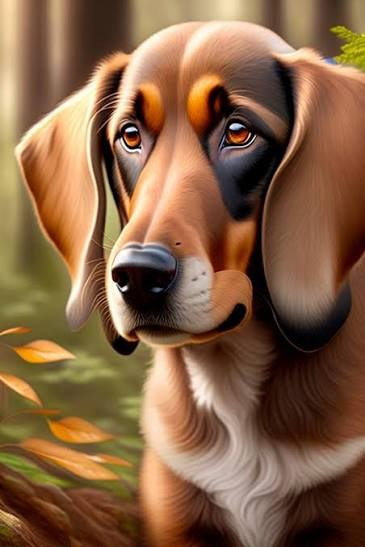

In [28]:
# ============================================================
# DEMO CELL 4 — Result + Image (FIXED)
# ============================================================
# Robust upload parsing — metadata missing bhi handle karta hai
# ============================================================

if not upload.value:
    print("⚠️ Pehle DEMO CELL 3 mein image upload karo")
else:
    # --- Robust upload parsing ---
    up = upload.value
    print("Debug — upload type:", type(up))

    # Case 1: tuple/list of dicts (older ipywidgets)
    if isinstance(up, (tuple, list)):
        file_info = up[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 2: dict of dicts (newer ipywidgets)
    elif isinstance(up, dict):
        # First item ka value lo
        file_info = list(up.values())[0]
        content = file_info['content']
        filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))

    # Case 3: list of dicts (some versions)
    else:
        # Try treating as iterable
        try:
            file_info = list(up)[0]
            content = file_info['content']
            filename = file_info.get('metadata', {}).get('name', file_info.get('name', 'uploaded.jpg'))
        except Exception as e:
            print(f"❌ Upload parse fail: {e}")
            content = None
            filename = 'unknown'

    if content is None:
        print("❌ Image read nahi ho payi — dobara upload karo")
    else:
        # Content kabhi bytes, kabhi memoryview hota hai
        if not isinstance(content, (bytes, bytearray)):
            content = bytes(content)

        img = Image.open(io.BytesIO(content)).convert('RGB')

        # --- Predict with TTA ---
        result = predict_image(img)

        # --- Convert to base64 for HTML display ---
        buf = io.BytesIO()
        img.save(buf, format='JPEG', quality=90)
        img_b64 = base64.b64encode(buf.getvalue()).decode()

        # --- Color based on prediction ---
        is_ai = result['label_idx'] == 1
        color = '#dc2626' if is_ai else '#16a34a'
        bg    = '#fef2f2' if is_ai else '#f0fdf4'

        # --- HTML output ---
        html = f"""
        <div style="display:flex; gap:24px; align-items:flex-start;
                    font-family: -apple-system, sans-serif;
                    padding:16px; background:{bg}; border-radius:12px;
                    border:2px solid {color}; max-width:800px;">

          <div style="flex:0 0 300px;">
            <img src="data:image/jpeg;base64,{img_b64}"
                 style="width:300px; border-radius:8px;
                        border:3px solid {color};
                        box-shadow:0 4px 12px rgba(0,0,0,0.1);"/>
          </div>

          <div style="flex:1; padding-top:8px;">
            <div style="font-size:13px; color:#666; margin-bottom:4px;">
              File: {filename}
            </div>

            <div style="font-size:32px; font-weight:700; color:{color};
                        margin-bottom:12px; line-height:1.1;">
              {result['label']}
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>AI Probability:</b>
              <span style="color:#dc2626; font-weight:600;">
                {result['ai_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:14px; color:#333; margin-bottom:6px;">
              <b>Real Probability:</b>
              <span style="color:#16a34a; font-weight:600;">
                {result['real_prob']*100:.2f}%
              </span>
            </div>

            <div style="font-size:12px; color:#888; margin-top:12px;
                        padding-top:12px; border-top:1px solid #ddd;">
              Threshold: {AI_THRESHOLD} &nbsp;|&nbsp;
              TTA: ON &nbsp;|&nbsp;
              IMG_SIZE: {IMG_SIZE}
            </div>
          </div>
        </div>
        """
        display(HTML(html))